In [1]:
# JulioPrajaSarbunan_202431152
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('hasil_scraping.csv')
df.head()

,nama,harga,harga_asli,rating,terjual,toko,lokasi,produk,kategori
0,Johnwin - Kaos Active Fashion Pria motif crew ...,133000,283600,5.0,3.0,Johnwin,Jakarta Barat,https://www.tokopedia.com/johnwin/johnwin-kaos...,Kaos
1,Cressida Kaos Kerah Regular Pria Multi Colour ...,254610,333700,5.0,2.0,Cressida,Bandung,https://www.tokopedia.com/cressida/cressida-ka...,Kaos
2,Kaos Distro Cowok ORUKA BULB Baju Pria Sablon ...,82450,85000,5.0,60.0,Oruka Cloth,Blitar,https://www.tokopedia.com/oruka-official/kaos-...,Kaos
3,Cressida Kaos Kerah Regular Pria Multi Colour ...,273900,323700,5.0,4.0,Cressida,Bandung,https://www.tokopedia.com/cressida/cressida-ka...,Kaos
4,Kaos Cowok Distro Yaris Baju Kaos T Shirt Pria...,97350,177000,5.0,6.0,Oruka Cloth,Blitar,https://www.tokopedia.com/oruka-official/kaos-...,Polo


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   nama        234 non-null    object 
 1   harga       234 non-null    int64  
 2   harga_asli  234 non-null    int64  
 3   rating      234 non-null    float64
 4   terjual     234 non-null    float64
 5   toko        234 non-null    object 
 6   lokasi      234 non-null    object 
 7   produk      234 non-null    object 
 8   kategori    234 non-null    object 
dtypes: float64(2), int64(2), object(5)
memory usage: 16.6+ KB


In [4]:
df.describe()

,harga,harga_asli,rating,terjual
count,234.000000,234.000000,234.000000,234.000000
mean,119875.854701,244001.307692,4.786325,8149.346154
std,66216.704313,134960.076345,0.182687,18864.375709
min,12500.000000,12500.000000,4.000000,1.000000
25%,72413.000000,139575.000000,4.700000,100.000000
50%,105900.000000,219444.500000,4.800000,2000.000000
75%,144762.500000,308025.000000,4.900000,10000.000000
max,365000.000000,640000.000000,5.000000,100000.000000


In [5]:
df.isna().sum()

,0
nama,0
harga,0
harga_asli,0
rating,0
terjual,0
toko,0
lokasi,0
produk,0
kategori,0


In [6]:
print(df['kategori'].unique())
# 0 = Jaket (jaket, hoodie, sweater)
# 1 = Kaos (kaos, polo shirt, t-shirt)

['Kaos' 'Polo' 'Jaket' 'Hoodie']


In [7]:
x = df.drop(['nama', 'toko', 'lokasi', 'produk', 'kategori'], axis=1)
y = df['kategori']

In [8]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)
print(dict(zip(le.classes_, le.transform(le.classes_))))
x = np.array(x, dtype=np.float64)
y = np.array(y, dtype=np.int64)

{'Hoodie': np.int64(0), 'Jaket': np.int64(1), 'Kaos': np.int64(2), 'Polo': np.int64(3)}


In [9]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

In [10]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
model.fit(x_train, y_train)

DecisionTreeClassifier()

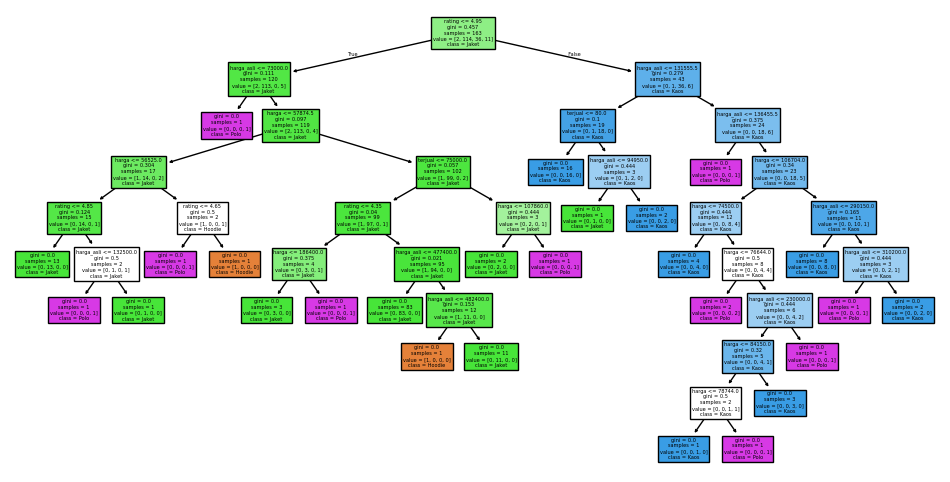

In [11]:
from sklearn import tree
plt.figure(figsize=(12, 6))
tree.plot_tree(model, filled=True,
               feature_names=['harga', 'harga_asli', 'rating', 'terjual'],
               class_names=le.classes_)
plt.show()

In [12]:
data_baru = np.array([[100000.0, 200000.0, 4.8, 500.0]])
hasil = model.predict(data_baru)
print(hasil, '->', le.inverse_transform(hasil))

[1] -> ['Jaket']


In [13]:
from sklearn.metrics import accuracy_score, classification_report
y_pred = model.predict(x_test)
print('Akurasi:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Akurasi: 0.7746478873239436
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.90      0.94      0.92        50
           2       0.54      0.78      0.64         9
           3       0.20      0.11      0.14         9

    accuracy                           0.77        71
   macro avg       0.41      0.46      0.43        71
weighted avg       0.73      0.77      0.75        71

